# FIFA World Cup 2026 — Linear Regression 2.1
## 03. Regression Modelling

**Objective:** Predict home-team goal_difference from the same eight historical predictors used in Data Preparation and EDA.

This notebook follows the following modelling stages:  data loading, splitting, baseline modelling, diagnostics, regularised regression, comparison and final evaluation. 
Run the Data Preparation notebook first to create Regression_2_1_Prepared_Data.csv

## Step 1 — Import libraries and load the prepared dataset

In [13]:
from pathlib import Path     # Import pathlib for handling file paths in a platform-independent way
import numpy as np            # Import numpy for numerical operations
import pandas as pd            # Import pandas for data manipulation and analysis
import matplotlib.pyplot as plt  # Import matplotlib for data visualization
from scipy import stats         # Import scipy for statistical functions
from sklearn.model_selection import TimeSeriesSplit, cross_validate, cross_val_predict, GridSearchCV  # Import scikit-learn model selection tools
from sklearn.pipeline import Pipeline  # Import scikit-learn pipeline for chaining transformers and estimators
from sklearn.impute import SimpleImputer  # Import scikit-learn imputer for handling missing values
from sklearn.preprocessing import StandardScaler  # Import scikit-learn scaler for feature scaling
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet  # Import scikit-learn linear models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Import scikit-learn metrics for model evaluation
from statsmodels.stats.outliers_influence import variance_inflation_factor  # Import VIF for multicollinearity check
import statsmodels.api as sm  # Import statsmodels for statistical modeling
import os  # Import os for operating system dependent functionality



In [14]:
pd.set_option("display.max_columns", None)     # Display all columns when printing DataFrames
file_path = Path("Regression_2_1_Prepared_Data.csv")  # Define the path to the prepared data file
if not file_path.exists():  # Check if the prepared data file exists
    raise FileNotFoundError("Run the ORIGINAL Regression 2.1 Data Preparation notebook first.")
df = pd.read_csv(file_path)  # Read the prepared data into a DataFrame
df["date"] = pd.to_datetime(df["date"], errors="raise")  # Convert the "date" column to datetime
df = df.sort_values(["date", "match_id"], kind="stable").reset_index(drop=True)  # Sort the DataFrame by date and match_id
print("Dataset shape:", df.shape)  # Print the shape of the DataFrame
display(df.head())  # Display the first few rows of the DataFrame

Dataset shape: (104, 14)


,match_id,date,Round_Number,Home_Team,Away_Team,Team_prior_matches,Opponent_prior_matches,Team_prior_goals_scored_avg,Opponent_prior_goals_scored_avg,Team_rest_days,Opponent_rest_days,Team_prior_win_rate,Opponent_prior_win_rate,goal_difference
0,1,2026-06-11 19:00:00.000002931,1,Mexico,South Africa,16,10,1.5,1.5,7,13,0.4,0.4,2
1,2,2026-06-12 01:59:59.999997068,1,South Korea,Czech Republic,7,7,1.9,2.0,1,12,0.7,0.6,1
2,3,2026-06-12 19:00:00.000002931,1,Canada,Bosnia and Herzegovina,11,4,1.0,1.1,7,14,0.3,0.3,0
3,4,2026-06-13 01:00:00.000002931,1,United States,Paraguay,17,2,2.2,1.4,1,8,0.6,0.7,3
4,8,2026-06-13 19:00:00.000002931,1,Qatar,Switzerland,10,5,0.9,2.7,7,13,0.1,0.6,0


## Step 2 — Define the target and eight predictors

In [15]:
target = "goal_difference"      # Define the target variable for regression
features = [  # Define the predictor variables for regression
    "Team_prior_matches", "Opponent_prior_matches",
    "Team_prior_goals_scored_avg", "Opponent_prior_goals_scored_avg",
    "Team_rest_days", "Opponent_rest_days",
    "Team_prior_win_rate", "Opponent_prior_win_rate"
]
assert len(features) == 8 and len(set(features)) == 8     # Ensure there are exactly 8 unique predictor variables
assert set(features + [target, "match_id", "date"]).issubset(df.columns)  # Ensure all required columns are present in the DataFrame
assert df["match_id"].is_unique, "Expected one observation per match."  # Ensure each match_id is unique
X = df[features].apply(pd.to_numeric, errors="raise")  # Convert predictor variables to numeric
y = pd.to_numeric(df[target], errors="raise")  # Convert target variable to numeric
assert y.notna().all()  # Ensure there are no missing values in the target variable
print("Target:", target)    # Print the name of the target variable and the corresponding values
print(y)  # Print the actual target values
print("Predictors:", features)  # Print the list of predictor variables
print("Missing values:")  # Print a message indicating the start of missing values check
display(X.isna().sum().to_frame("Missing"))  # Display the number of missing values for each predictor variable
print("Target missing values:")  # Print a message indicating the start of missing values check for the target variable
display(pd.DataFrame({"Missing": [y.isna().sum()]}, index=[target]))  # Display the number of missing values for the target variable

Target: goal_difference
0      2
1      1
2      0
3      3
4      0
      ..
99     2
100   -2
101   -1
102   -2
103    1
Name: goal_difference, Length: 104, dtype: int64
Predictors: ['Team_prior_matches', 'Opponent_prior_matches', 'Team_prior_goals_scored_avg', 'Opponent_prior_goals_scored_avg', 'Team_rest_days', 'Opponent_rest_days', 'Team_prior_win_rate', 'Opponent_prior_win_rate']
Missing values:


,Missing
Team_prior_matches,0
Opponent_prior_matches,0
Team_prior_goals_scored_avg,0
Opponent_prior_goals_scored_avg,0
Team_rest_days,0
Opponent_rest_days,0
Team_prior_win_rate,0
Opponent_prior_win_rate,0


Target missing values:


,Missing
goal_difference,0


Note on the Round 1 values:
The original dataset may use zeros as placeholders where a team has no prior tournament matches. These values are **retained exactly as supplied**, not filled from `results.csv`. This limitation should be mentioned because zero placeholder may be substantively different from a genuine zero-day rest period.

## Step 3 — Chronological train–test split

In [16]:
# Earlier fixtures are used for training; the final 20% are held out.
cutoff = int(len(df) * 0.80)        # Define the cutoff index for splitting the data into training and test sets.   This corresponds to the first 80% of the data for training and the remaining 20% for testing.
X_train, X_test = X.iloc[:cutoff], X.iloc[cutoff:]   # Split the predictor variables into training and test sets based on the cutoff index.
y_train, y_test = y.iloc[:cutoff], y.iloc[cutoff:]   # Split the target variable into training and test sets based on the cutoff index.
train_info, test_info = df.iloc[:cutoff], df.iloc[cutoff:]   # Split the original DataFrame into training and test sets based on the cutoff index.
assert train_info["date"].max() <= test_info["date"].min()    # Ensure that the latest training date is not after the earliest test date.   This helps maintain the temporal order of the data.
assert set(train_info["match_id"]).isdisjoint(test_info["match_id"])    # Ensure that there are no overlapping match IDs between the training and test sets.
print("Training observations:", len(X_train), "| Test observations:", len(X_test))  # Print the number of observations in the training and test sets.
print("Train dates:", train_info["date"].min(), "to", train_info["date"].max())    # Print the range of training dates.
print("Test dates:", test_info["date"].min(), "to", test_info["date"].max())    # Print the range of test dates.

Training observations: 83 | Test observations: 21
Train dates: 2026-06-11 19:00:00.000002931 to 2026-07-02 19:00:00.000002931
Test dates: 2026-07-02 22:59:59.999997068 to 2026-07-19 19:00:00.000002931


The test set is held out until model selection is complete. A chronological split is used because the objective is to predict later matches from earlier information. If several matches share the exact same date and no reliable kickoff order is available,  we check the boundary manually.

## Step 4 — Baseline Multiple Linear Regression

In [17]:
def make_pipeline(regressor):  # Create a pipeline with imputation, scaling, and the specified regressor.
    return Pipeline([     # Define the steps of the pipeline: imputation, scaling, and the regressor.
        ("imputer", SimpleImputer(strategy="median")),  # Impute missing values using the median of each column.
        ("scaler", StandardScaler()),  # Standardize features by removing the mean and scaling to unit variance.
        ("regressor", regressor)  # The specified regression model to be used in the pipeline.
    ])

baseline_model = make_pipeline(LinearRegression())  # Create the baseline model pipeline with a linear regression estimator.
# Time-series CV respects observation order. Scaling and imputation are fitted inside each fold.
cv = TimeSeriesSplit(n_splits=5)  # Define a time-series cross-validator with 5 splits.
scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}  # Define the scoring metrics for cross-validation.
base_cv = cross_validate(baseline_model, X_train, y_train, cv=cv, scoring=scoring)  # Perform cross-validation on the baseline model.
baseline_model.fit(X_train, y_train)  # Fit the baseline model on the training data.
print("Baseline training RMSE:", round(np.sqrt(mean_squared_error(y_train, baseline_model.predict(X_train))), 3))  # Print the training RMSE for the baseline model.
print("Baseline CV RMSE:", round(-base_cv["test_RMSE"].mean(), 3))  # Print the cross-validated RMSE for the baseline model.
print("Baseline CV MAE:", round(-base_cv["test_MAE"].mean(), 3))  # Print the cross-validated MAE for the baseline model.
print("Baseline CV R²:", round(base_cv["test_R2"].mean(), 3))  # Print the cross-validated R² for the baseline model.

Baseline training RMSE: 1.849
Baseline CV RMSE: 2.16
Baseline CV MAE: 1.701
Baseline CV R²: -0.163


## Step 5 — Baseline diagnostics

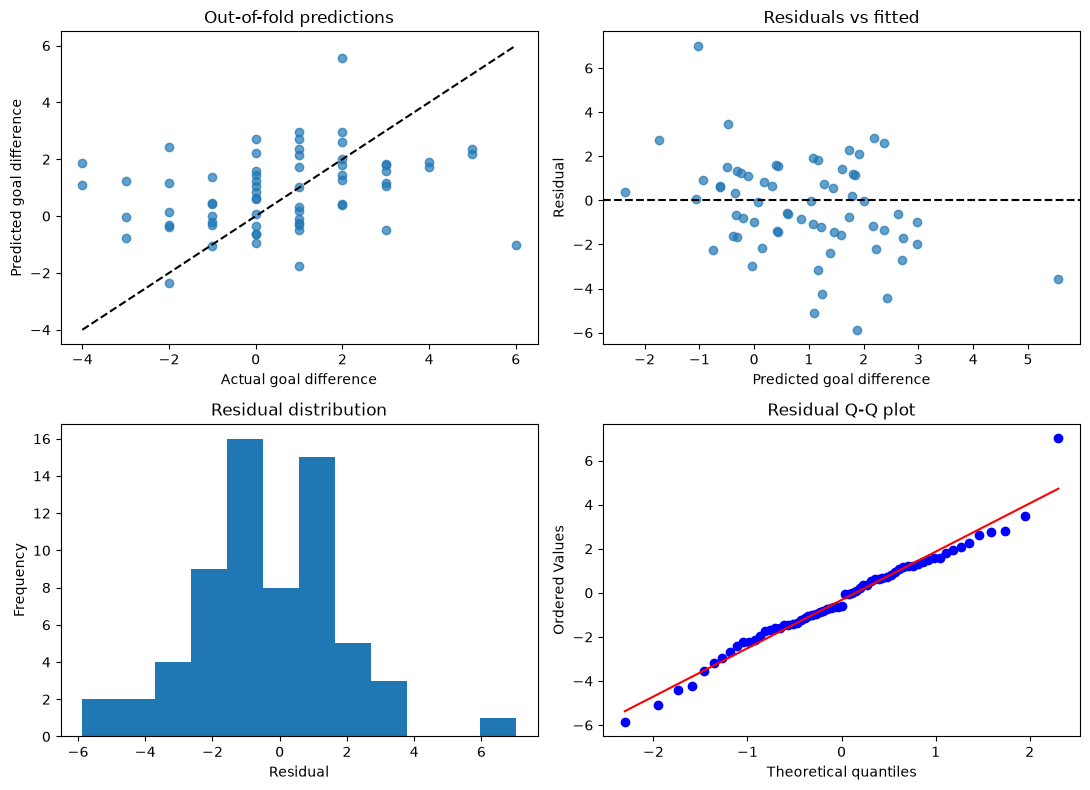

Out-of-fold RMSE: 2.184


In [18]:
# Out-of-fold predictions: only predict validation folds; initial training block has no CV prediction.
oof_pred = pd.Series(np.nan, index=X_train.index, dtype=float)    # Initialize a Series to store out-of-fold predictions, with NaN for all training indices initially.
for tr_idx, val_idx in cv.split(X_train):    # Iterate over each train-validation split in the time-series cross-validation.
    fold_model = make_pipeline(LinearRegression())    # Create a new pipeline for the current fold.
    fold_model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])    # Fit the model on the training portion of the current fold.
    oof_pred.iloc[val_idx] = fold_model.predict(X_train.iloc[val_idx])    # Predict on the validation portion and store the predictions.
valid = oof_pred.notna()    # Identify the indices where out-of-fold predictions are available.
observed = y_train.loc[valid]    # Extract the observed values corresponding to the valid predictions.
predicted = oof_pred.loc[valid]    # Extract the predicted values corresponding to the valid predictions.
residuals = observed - predicted    # Compute the residuals for the valid predictions.



fig, axes = plt.subplots(2, 2, figsize=(11, 8))    # Create a 2x2 subplot grid for diagnostic plots.
axes[0,0].scatter(observed, predicted, alpha=.7)    # Scatter plot of observed vs predicted values.
lo = min(observed.min(), predicted.min()); hi = max(observed.max(), predicted.max())    # Determine the limits for the reference line.
axes[0,0].plot([lo, hi], [lo, hi], '--', color='black')    # Plot the reference line y=x.
axes[0,0].set(xlabel='Actual goal difference', ylabel='Predicted goal difference', title='Out-of-fold predictions')    # Set labels and title for the scatter plot.
axes[0,1].scatter(predicted, residuals, alpha=.7)    # Scatter plot of residuals vs predicted values.
axes[0,1].axhline(0, linestyle='--', color='black')    # Add a horizontal reference line at 0.
axes[0,1].set(xlabel='Predicted goal difference', ylabel='Residual', title='Residuals vs fitted')    # Set labels and title for the residual plot.
axes[1,0].hist(residuals, bins=12)    # Histogram of residuals.
axes[1,0].set(xlabel='Residual', ylabel='Frequency', title='Residual distribution')    # Set labels and title for the histogram.
stats.probplot(residuals, dist='norm', plot=axes[1,1])    # Q-Q plot of residuals to assess normality.
axes[1,1].set_title('Residual Q-Q plot')    # Set title for the Q-Q plot.
plt.tight_layout(); plt.show()
print('Out-of-fold RMSE:', round(np.sqrt(mean_squared_error(observed, predicted)), 3))    # Print the out-of-fold RMSE.

In [19]:
# Check multicollinearity on training data only.
X_imp = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_train), columns=features)  # Impute missing values in the training data using the median strategy.
X_vif = sm.add_constant(X_imp, has_constant='add')  # Add a constant term to the imputed training data for VIF calculation.
vif_table = pd.DataFrame({
    'Predictor': features,
    'VIF': [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(features))]  # Calculate VIF for each predictor.
}).sort_values('VIF', ascending=False)  # Sort the VIF table in descending order of VIF values.
display(vif_table)  # Display the VIF table.

coefficients = pd.DataFrame({
    'Predictor': features,
    'Standardised coefficient': baseline_model.named_steps['regressor'].coef_  # Extract the standardized coefficients from the baseline model.
}).sort_values('Standardised coefficient', key=lambda x: x.abs(), ascending=False)  # Sort by the absolute value of the coefficients.
display(coefficients)  # Display the coefficients table.

,Predictor,VIF
7,Opponent_prior_win_rate,1.772002
3,Opponent_prior_goals_scored_avg,1.635551
2,Team_prior_goals_scored_avg,1.583354
6,Team_prior_win_rate,1.575683
0,Team_prior_matches,1.187251
4,Team_rest_days,1.157808
1,Opponent_prior_matches,1.045835
5,Opponent_rest_days,1.042104


,Predictor,Standardised coefficient
7,Opponent_prior_win_rate,-0.637792
6,Team_prior_win_rate,0.531027
0,Team_prior_matches,0.365692
5,Opponent_rest_days,0.249393
3,Opponent_prior_goals_scored_avg,-0.207637
4,Team_rest_days,0.203469
2,Team_prior_goals_scored_avg,0.145142
1,Opponent_prior_matches,-0.087206


### Diagnostic interpretation

We examined the residual plots to check for patterns, changes in spread and unusual values that could affect the model. We also used VIF to check whether some predictors were strongly related to each other. Since goal difference can be positive, negative or zero, negative predictions are acceptable in this analysis.

## Step 6 — Tune Ridge, Lasso and Elastic Net

In [20]:
alpha_grid = np.logspace(-3, 2, 25)     # Define a grid of alpha values for hyperparameter tuning in Ridge, Lasso, and Elastic Net models.
searches = { # Dictionary to store GridSearchCV objects for Ridge, Lasso, and Elastic Net models.
    'Ridge': GridSearchCV(make_pipeline(Ridge()), {'regressor__alpha': alpha_grid}, cv=cv, scoring=scoring, refit='RMSE'),  # Grid search for Ridge regression.
    'Lasso': GridSearchCV(make_pipeline(Lasso(max_iter=50000)), {'regressor__alpha': alpha_grid}, cv=cv, scoring=scoring, refit='RMSE'),  # Grid search for Lasso regression.
    'Elastic Net': GridSearchCV(make_pipeline(ElasticNet(max_iter=50000)), {
        'regressor__alpha': alpha_grid, 'regressor__l1_ratio': [0.2, 0.5, 0.8]
    }, cv=cv, scoring=scoring, refit='RMSE')  # Grid search for Elastic Net regression.
}
for name, search in searches.items():
    search.fit(X_train, y_train)  # Fit the grid search on the training data.
    print(name, 'best parameters:', search.best_params_)  # Print the best hyperparameters for each model.

Ridge best parameters: {'regressor__alpha': np.float64(38.31186849557293)}
Lasso best parameters: {'regressor__alpha': np.float64(0.19573417814876617)}
Elastic Net best parameters: {'regressor__alpha': np.float64(0.510896977450693), 'regressor__l1_ratio': 0.2}


## Step 7 — Compare models using training-only cross-validation

,Model,CV_RMSE,CV_MAE,CV_R2
0,Ridge,2.034,1.589,-0.018
1,Elastic Net,2.054,1.592,-0.039
2,Lasso,2.091,1.614,-0.078
3,Linear Regression,2.160,1.701,-0.163


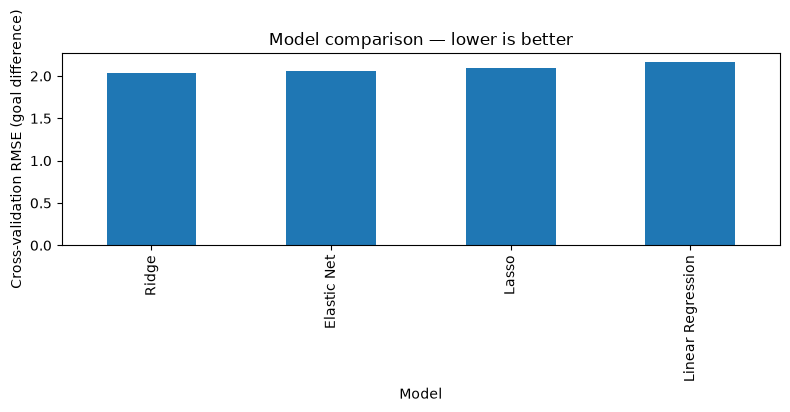

In [21]:
comparison_rows = [{   # Initialize the comparison table with the baseline Linear Regression model.
    'Model': 'Linear Regression',
    'CV_RMSE': -base_cv['test_RMSE'].mean(),
    'CV_MAE': -base_cv['test_MAE'].mean(),
    'CV_R2': base_cv['test_R2'].mean()
}]
for name, search in searches.items(): # Iterate over each model and its corresponding GridSearchCV object.
    i = search.best_index_      # Get the index of the best hyperparameter combination for the current model.
    comparison_rows.append({ # Append the current model's performance metrics to the comparison table.
        'Model': name,
        'CV_RMSE': -search.cv_results_['mean_test_RMSE'][i],
        'CV_MAE': -search.cv_results_['mean_test_MAE'][i],
        'CV_R2': search.cv_results_['mean_test_R2'][i]
    })
cv_comparison = pd.DataFrame(comparison_rows).sort_values('CV_RMSE').reset_index(drop=True)  # Create a DataFrame for comparison and sort by CV_RMSE.
display(cv_comparison.round(3))  # Display the comparison table rounded to 3 decimal places.
cv_comparison.plot.bar(x='Model', y='CV_RMSE', legend=False, figsize=(8, 4))  # Plot a bar chart for CV_RMSE comparison.
plt.ylabel('Cross-validation RMSE (goal difference)')  # Set the y-axis label.
plt.title('Model comparison — lower is better')  # Set the plot title.
plt.tight_layout(); plt.show()  # Adjust layout and display the plot.

## Step 8 — Select the model and evaluate the untouched test set

In [22]:
best_name = cv_comparison.loc[0, 'Model']   # Select the model with the lowest CV_RMSE as the best model.   
models = {'Linear Regression': baseline_model, **{name: search.best_estimator_ for name, search in searches.items()}}  # Create a dictionary of all models including the baseline and the best estimators from the grid searches.
final_model = models[best_name]   # Retrieve the final model based on the best CV_RMSE.
final_predictions = final_model.predict(X_test)  # Generate predictions on the test set using the selected final model.
mean_baseline_prediction = np.repeat(y_train.mean(), len(y_test))  # Create a baseline prediction using the mean of the training target.

def metrics(actual, pred):  #Define a function to calculate common regression metrics: MAE, MSE, RMSE, and R2.
    return {'MAE': mean_absolute_error(actual, pred), 
            'MSE': mean_squared_error(actual, pred),
            'RMSE': np.sqrt(mean_squared_error(actual, pred)),
            'R2': r2_score(actual, pred)}

final_results = pd.DataFrame([ # Create a DataFrame to store the final evaluation results for the selected model and the baseline.
    {'Model': best_name, **metrics(y_test, final_predictions)},
    {'Model': 'Training-mean baseline', **metrics(y_test, mean_baseline_prediction)}
])
print('Selected model:', best_name) # Print the name of the selected best model based on CV_RMSE.
display(final_results.round(4))  # Display the final evaluation results rounded to 4 decimal places.

Selected model: Ridge


,Model,MAE,MSE,RMSE,R2
0,Ridge,1.4279,2.9468,1.7166,-0.2568
1,Training-mean baseline,1.4263,3.0521,1.7470,-0.3017


## Step 9 — Final predictions, residuals and coefficients

,match_id,date,Home_Team,Away_Team,Actual_Goal_Difference,Predicted_Goal_Difference,Residual
83,83,2026-07-02 22:59:59.999997068,Portugal,Croatia,1,0.368039,0.631961
84,85,2026-07-03 03:00:00.000000000,Switzerland,Algeria,2,1.000253,0.999747
85,88,2026-07-03 18:00:00.000000000,Australia,Egypt,0,0.846730,-0.846730
86,86,2026-07-03 22:00:00.000002931,Argentina,Cape Verde,1,1.790206,-0.790206
87,87,2026-07-04 01:30:00.000000000,Colombia,Ghana,1,1.131790,-0.131790
88,90,2026-07-04 16:59:59.999997068,Canada,Morocco,-3,-0.544419,-2.455581
89,89,2026-07-04 21:00:00.000000000,Paraguay,France,-1,-0.479815,-0.520185
90,91,2026-07-05 19:59:59.999997068,Brazil,Norway,-1,0.254769,-1.254769
91,92,2026-07-06 01:00:00.000002931,Mexico,England,-1,1.097947,-2.097947
92,93,2026-07-06 19:00:00.000002931,Portugal,Spain,-1,0.743974,-1.743974


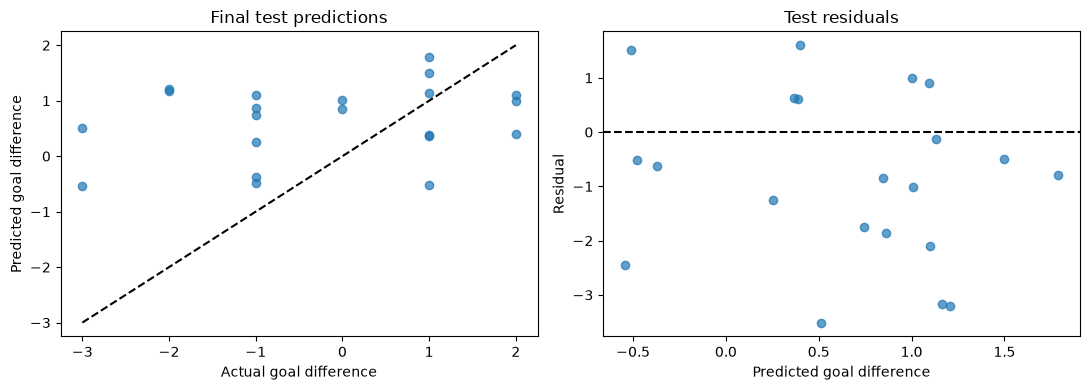

,Predictor,Standardised coefficient
7,Opponent_prior_win_rate,-0.376395
6,Team_prior_win_rate,0.305136
3,Opponent_prior_goals_scored_avg,-0.255133
0,Team_prior_matches,0.227691
5,Opponent_rest_days,0.141056
2,Team_prior_goals_scored_avg,0.117071
4,Team_rest_days,0.114961
1,Opponent_prior_matches,-0.087425


In [23]:
prediction_table = test_info[['match_id', 'date', 'Home_Team', 'Away_Team']].copy() # Create a table to store the test set predictions along with match information.
prediction_table['Actual_Goal_Difference'] = y_test.to_numpy()  # Add the actual goal difference from the test set.
prediction_table['Predicted_Goal_Difference'] = final_predictions  # Add the predicted goal difference from the final model.
prediction_table['Residual'] = y_test.to_numpy() - final_predictions  # Calculate the residuals (actual - predicted).
display(prediction_table.head(10))    # Display the first 10 rows of the prediction table.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # Create a figure with two subplots for visualizing predictions and residuals.
axes[0].scatter(y_test, final_predictions, alpha=.7)  # Scatter plot of actual vs predicted goal difference.
lo = min(y_test.min(), final_predictions.min()); hi = max(y_test.max(), final_predictions.max())
axes[0].plot([lo, hi], [lo, hi], '--', color='black')  # Plot a reference line for perfect predictions.
axes[0].set(xlabel='Actual goal difference', ylabel='Predicted goal difference', title='Final test predictions')
axes[1].scatter(final_predictions, prediction_table['Residual'], alpha=.7)  # Scatter plot of predicted vs residuals.
axes[1].axhline(0, linestyle='--', color='black')  # Reference line at zero residual.
axes[1].set(xlabel='Predicted goal difference', ylabel='Residual', title='Test residuals')
plt.tight_layout(); plt.show()
final_coefficients = pd.DataFrame({  # Create a DataFrame to display the standardized coefficients of the final model.
    'Predictor': features,
    'Standardised coefficient': final_model.named_steps['regressor'].coef_
}).sort_values('Standardised coefficient', key=lambda x: x.abs(), ascending=False)
display(final_coefficients)  # Display the sorted coefficients.     

## Step 10 — Save results and final validation

In [24]:
# Create the final model coefficient table
final_coefficients = pd.DataFrame({  # Create a DataFrame to store the final model coefficients.
    'Predictor': features,
    'Standardised coefficient': final_model.named_steps['regressor'].coef_
})

# Arrange predictors by the absolute size of their coefficients
final_coefficients = final_coefficients.sort_values(  
    'Standardised coefficient',
    key=lambda x: x.abs(),
    ascending=False
)

# Export model comparison results
cv_comparison.to_csv(
    'Regression_2_1_Model_Comparison.csv',
    index=False
)

# Export final test predictions
prediction_table.to_csv(
    'Regression_2_1_Test_Predictions.csv',
    index=False
)

# Export final model coefficients
final_coefficients.to_csv(
    'Regression_2_1_Model_Coefficients.csv',
    index=False
)

# Validate the modelling results
assert len(features) == 8
assert len(X_train) + len(X_test) == len(df)
assert np.isfinite(final_predictions).all()
assert set(train_info['match_id']).isdisjoint(test_info['match_id'])

print("Validation passed.")
print("Model comparison, test predictions and coefficients saved successfully.")

display(final_coefficients.round(4))

Validation passed.
Model comparison, test predictions and coefficients saved successfully.


,Predictor,Standardised coefficient
7,Opponent_prior_win_rate,-0.3764
6,Team_prior_win_rate,0.3051
3,Opponent_prior_goals_scored_avg,-0.2551
0,Team_prior_matches,0.2277
5,Opponent_rest_days,0.1411
2,Team_prior_goals_scored_avg,0.1171
4,Team_rest_days,0.1150
1,Opponent_prior_matches,-0.0874


## Modelling conclusion

In comparing the four regression models,Ridge Regression performed better than ordinary Linear Regression during cross-validation, with a lower RMSE of 2.034 compared with 2.160. However, its negative test R² of -0.257 shows that it did not perform better than a simple average prediction on the test data. This suggests that the eight predictors have limited ability to predict World Cup goal differences accurately.